# Example of the aitlas toolbox in the context of change detection

The Bandon dataset contains change labels between 3 time steps: t1 vs t2, t2 vs t3 and t1 vs t3.

## Import the required packages

In [ ]:
from aitlas.datasets import BandonDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Total number of patches: 1689


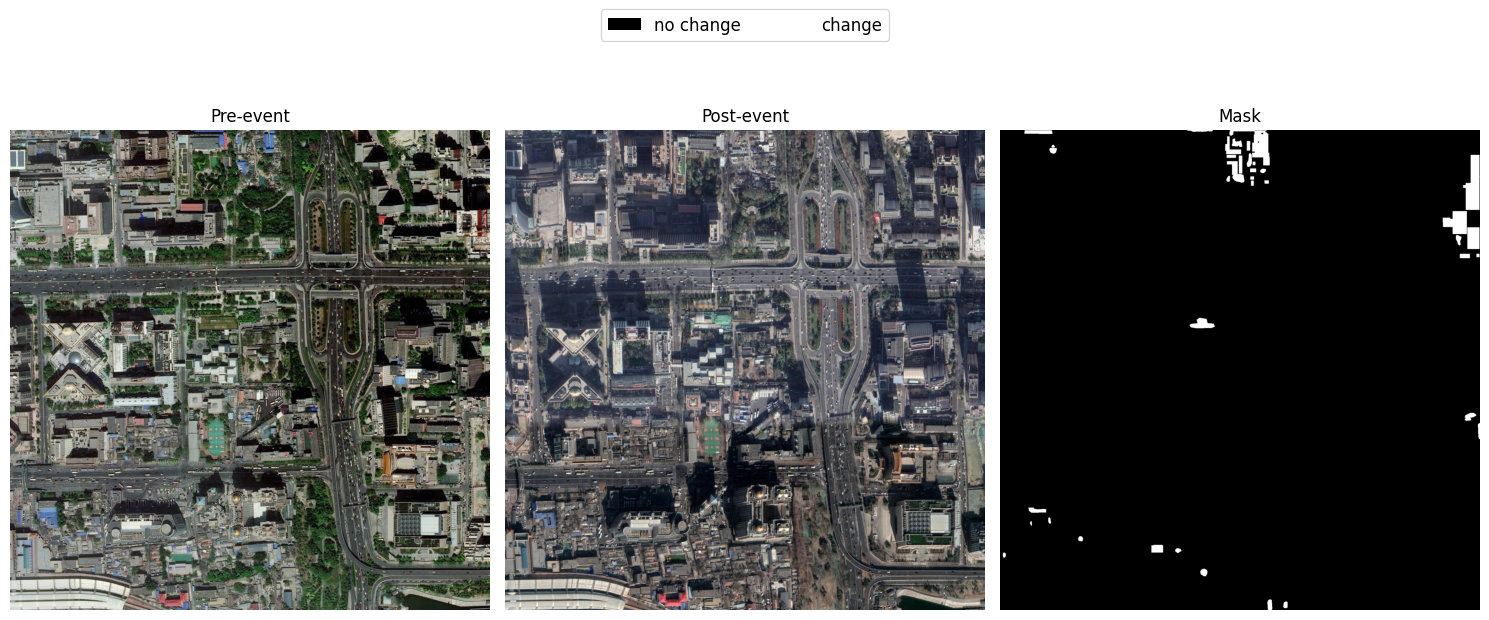

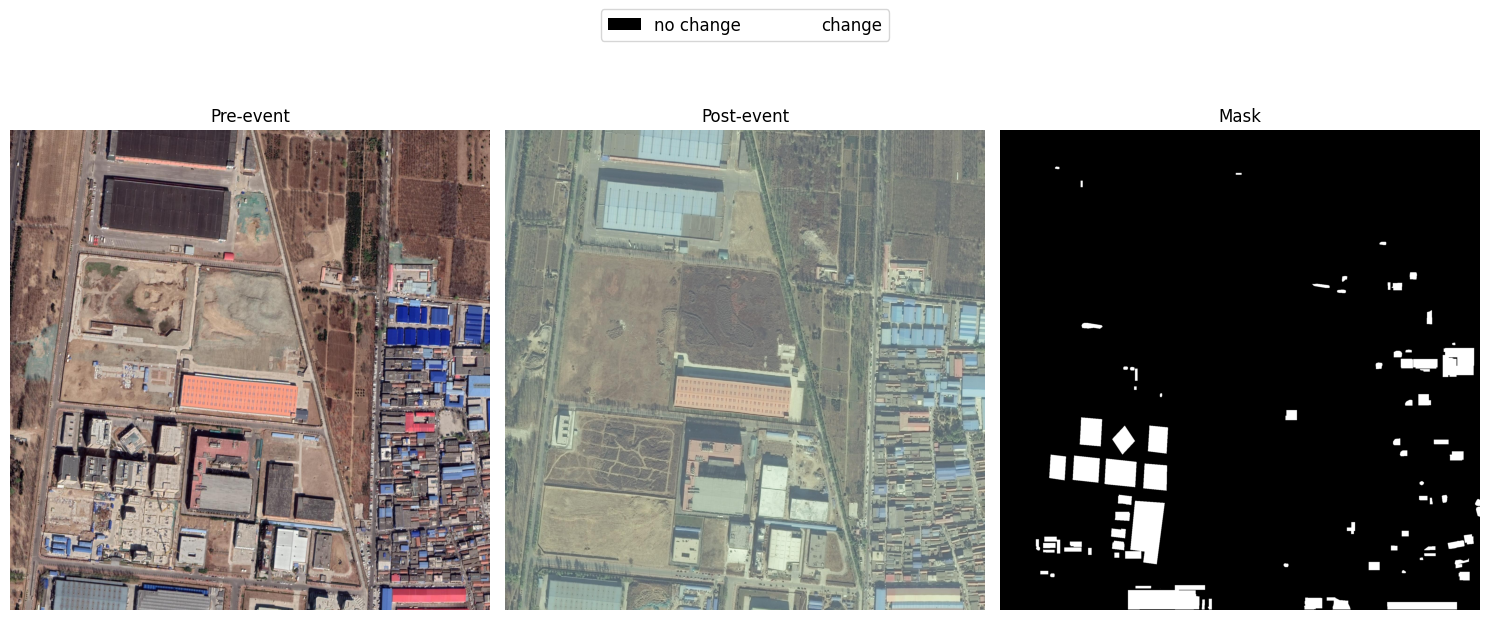

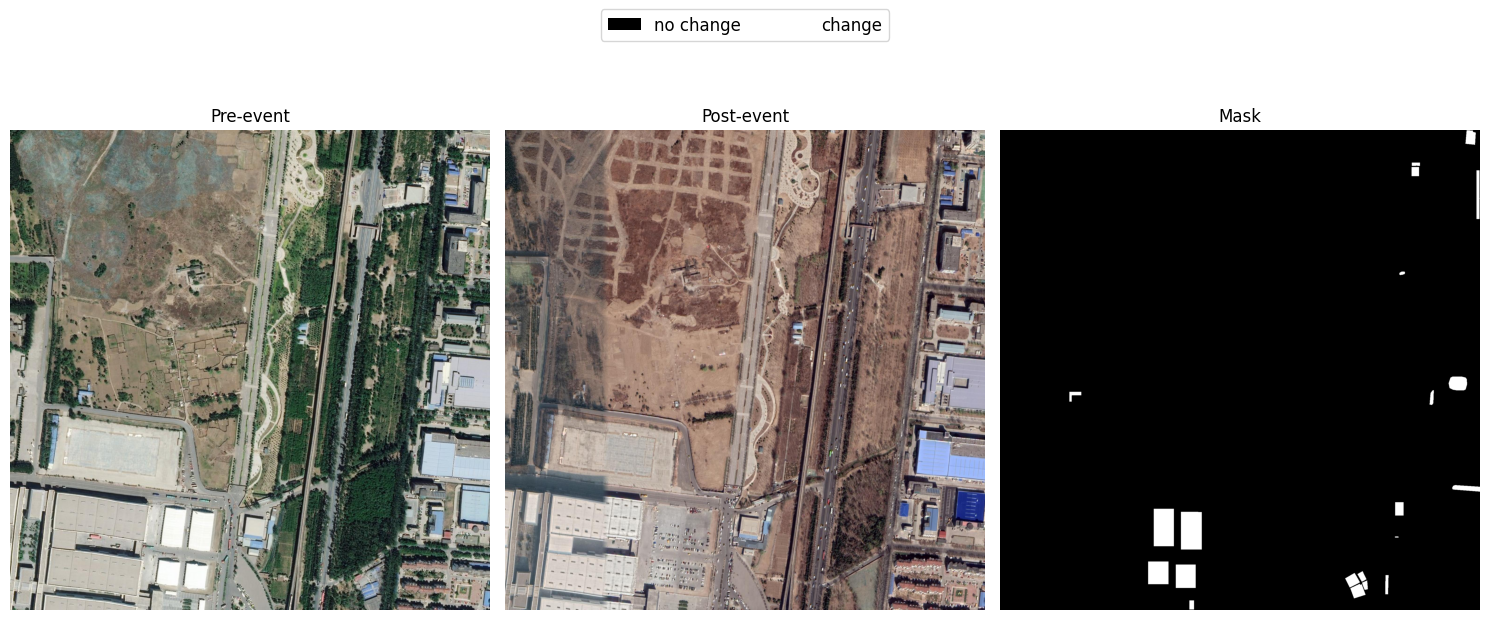

In [ ]:
dataset_config = {
    "data_dir" : "./data/bandon/train",
    "csv_file": "./data/bandon/list_BANDON_train.txt",
}
dataset = BandonDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(100);
dataset.show_image(1000);
dataset.show_image(22);

In [74]:
dataset.data_distribution_table()

,Number of pixels
no change,6.889125e+09
change,1.950543e+08


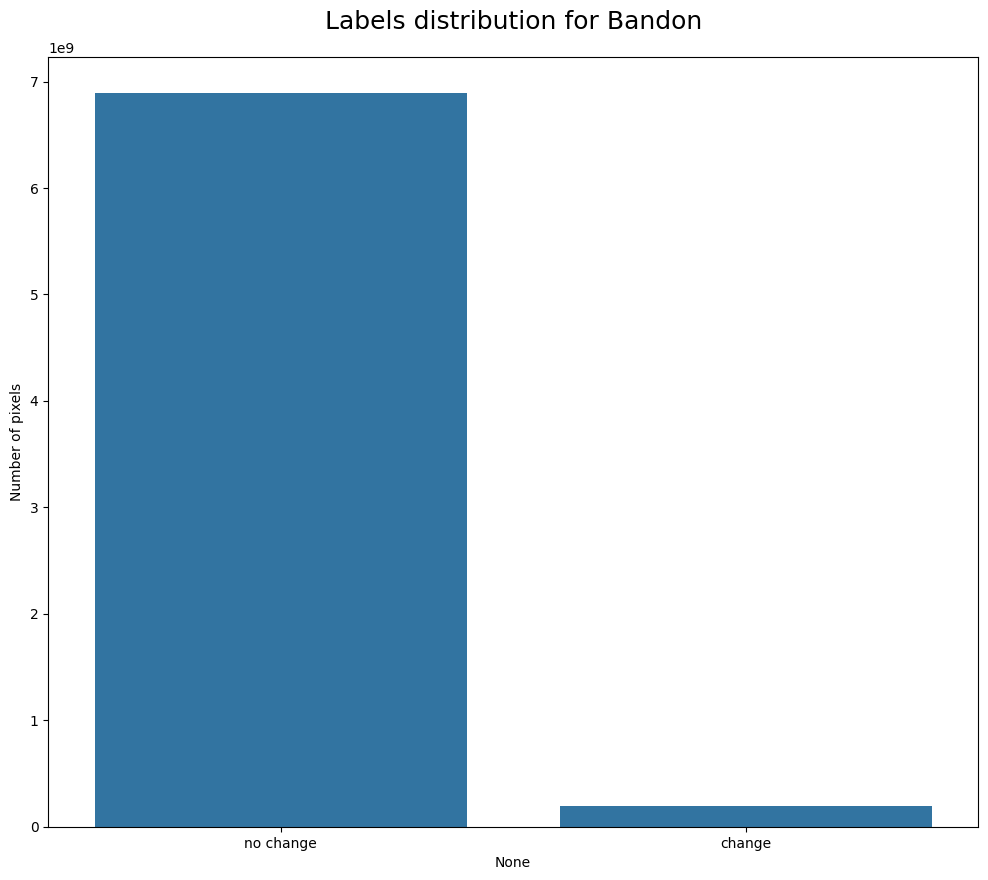

In [75]:
dataset.data_distribution_barchart();

## Load training and test data

Original train/test splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/bandon/train",
    "csv_file": "./data/bandon/list_BANDON_train.txt",
    "split": "original",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = BandonDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/bandon/val",
    "csv_file": "./data/bandon/list_BANDON_val.txt",
    "split": "original",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = BandonDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(1689, 202)

New 60/20/20 splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/bandon/",
    "csv_file": "./data/bandon/bandon_train.csv",
    "split": "new",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = BandonDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/bandon/",
    "csv_file": "./data/bandon/bandon_val.csv",
    "split": "new",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = BandonDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(1258, 420)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/bandon"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [15]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-27 08:33:08,125 INFO Starting training.
training: 100%|██████████| 53/53 [02:09<00:00,  2.44s/it]
2026-01-27 08:35:17,530 INFO epoch: 1, loss:  0.27683
testing on train set: 100%|██████████| 53/53 [02:06<00:00,  2.38s/it]
2026-01-27 08:37:24,845 INFO Accuracy:0.4200101844512054, Accuracy per Class:[0.22073477 0.6192856 ], Precision Micro:0.330987578524341, Precision Macro:0.49328850381787576, Precision Weighted:0.9595820518194594, Precision per Class:[0.97241753 0.01415948], Recall Micro:0.19315029540842396, Recall Macro:0.30154446131444124, Recall Weighted:0.19315029540842396, Recall per Class:[0.19016657 0.41292235], F1_score Micro:0.24394477769296283, F1_score Macro:0.17275062479814002, F1_score Weighted:0.31422681502855554, F1_score per Class:[0.31812117 0.02738008], IOU:0.13891634761489915, IOU mean:0.10151318308845969, IOU per Class:[0.18914631 0.01388006]
training: 100%|██████████| 53/53 [02:02<00:00,  2.31s/it]
2026-01-27 08:39:27,440 INFO epoch: 2, loss:  0.22279
testi

## Predictions

2026-01-27 11:33:56,559 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/bandon/checkpoint.pth.tar
2026-01-27 11:33:56,844 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/bandon/checkpoint.pth.tar at epoch 51


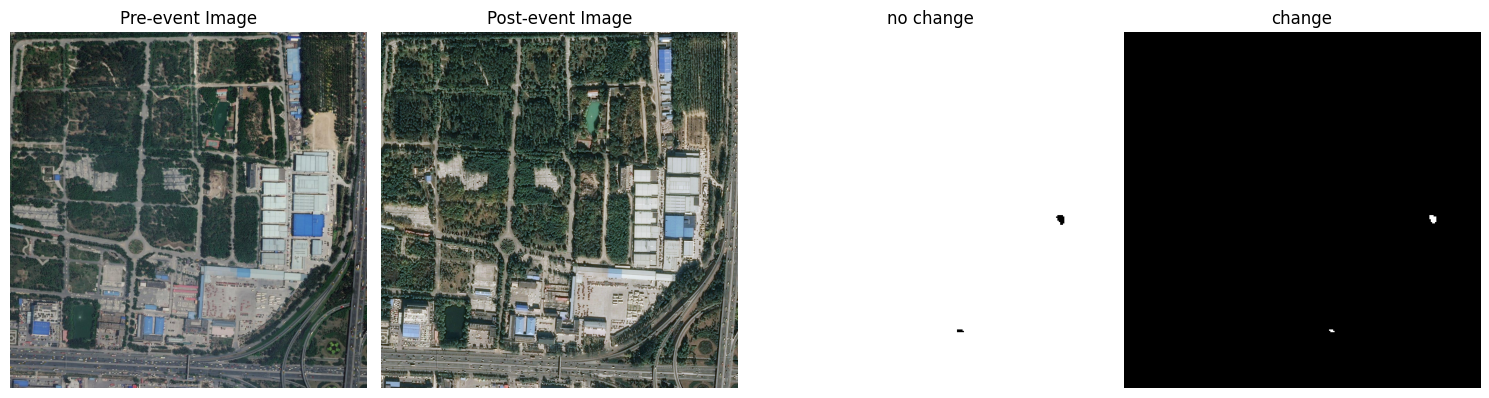

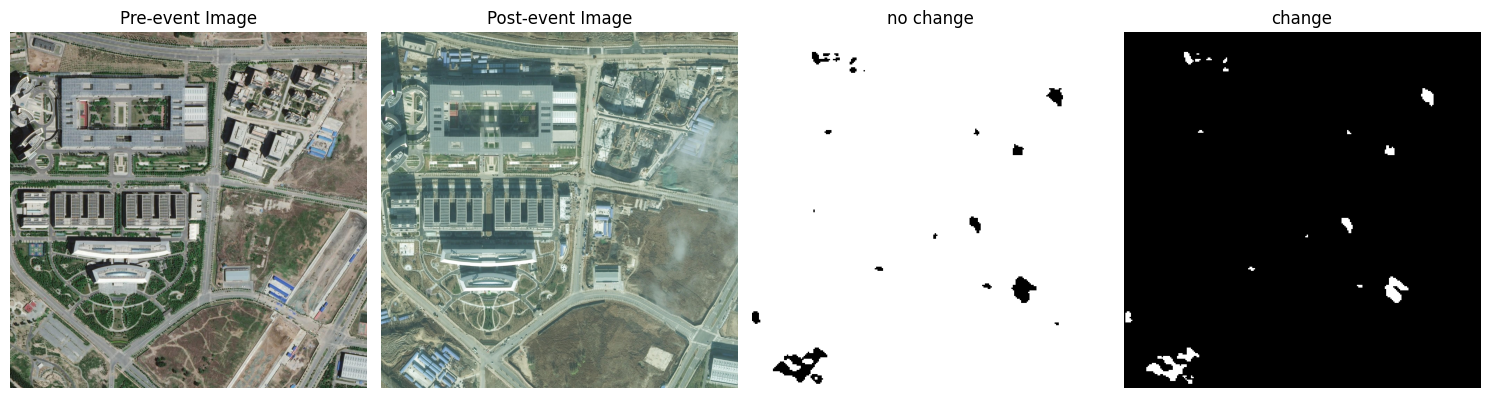

In [ ]:
model_path = "./data/experiments/bandon/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("./data/bandon/test/test/imgs/bj/t1/L81_00639_784071.jpg")
image2 = image_loader("./data/bandon/test/test/imgs/bj/t3/L81_00639_784071.jpg")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("./data/bandon/test/test/imgs/bj/t1/L81_00887_784127.jpg")
image2 = image_loader("./data/bandon/test/test/imgs/bj/t3/L81_00887_784127.jpg")
fig = model.predict_masks(image1, image2, labels, transform)